In [1]:
# Verificar se a GPU T4 está ativa e qual a VRAM disponível
!nvidia-smi

# Instalar dependências silenciosamente
!pip install -q -U transformers datasets peft accelerate bitsandbytes trl rouge-score openai gradio python-dotenv

Fri Nov 20 17:40:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Autenticação e Carga do Dataset

In [2]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata
from huggingface_hub import login
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# 1. Login seguro no Hugging Face usando os Secrets do Colab
hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)

# 2. Carregar o dataset Bitext Customer Support
DATASET_ID = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
raw_dataset = load_dataset(DATASET_ID, split="train")

# Converter para DataFrame do Pandas para análise exploratória
df = raw_dataset.to_pandas()
print(f"Total de registros carregados: {len(df):,}")
print(f"Colunas disponíveis: {list(df.columns)}")
df.head(3)

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

Total de registros carregados: 26,872
Colunas disponíveis: ['flags', 'instruction', 'category', 'intent', 'response']


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...


Análise Exploratória (EDA) — Intenções e Qualidade dos Dados

Valores nulos por coluna:
 flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Mensagens duplicadas exatas: 2237
Total após deduplicação: 24,635

Número total de intenções únicas: 27

Distribuição por intenção:
intent
contact_customer_service    1000
complaint                   1000
check_payment_methods        999
contact_human_agent          999
newsletter_subscription      999
payment_issue                999
delivery_period              999
registration_problems        999
place_order                  998
review                       997
check_refund_policy          997
set_up_shipping_address      997
recover_password             995
change_shipping_address      973
check_cancellation_fee       950
check_invoice                921
delete_account               918
get_refund                   918
get_invoice                  909
create_account               892
change_order                 870
switch_account               862
track_ord

/tmp/ipykernel_3507/1147121492.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=intents.values, y=intents.index, palette="viridis")


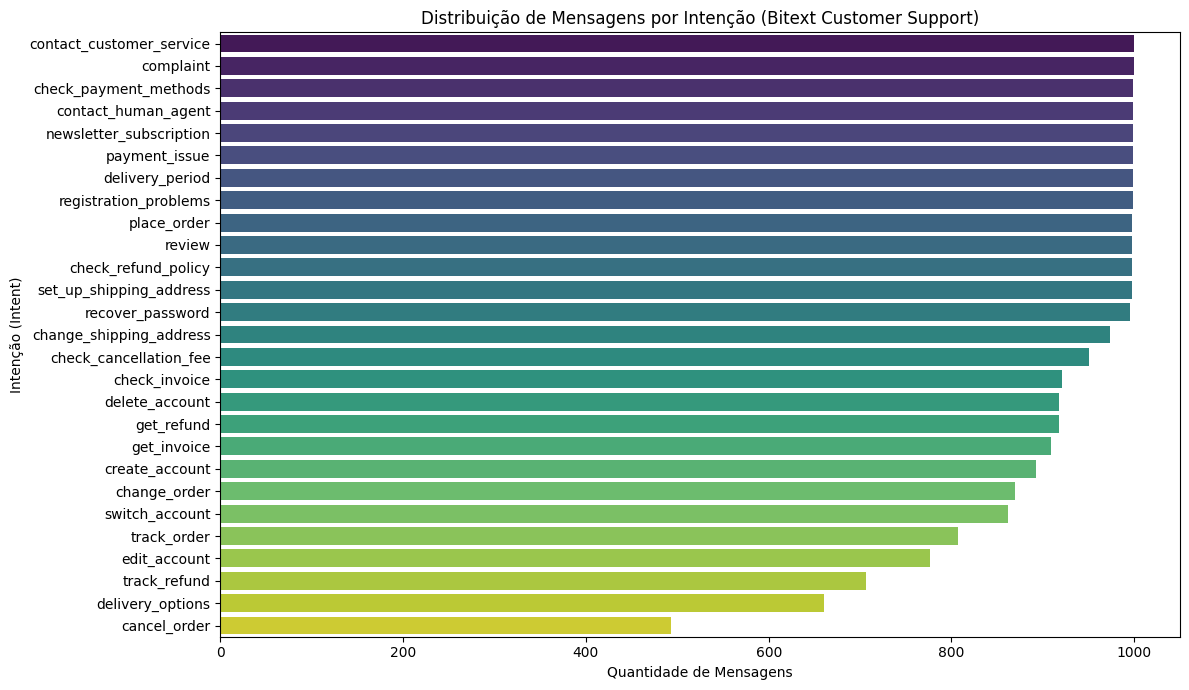

In [3]:
# Verificar valores nulos ou duplicados
print("Valores nulos por coluna:\n", df.isnull().sum())
print(f"\nMensagens duplicadas exatas: {df.duplicated(subset=['instruction']).sum()}")

# Remover duplicatas exatas na mensagem de entrada, se houver, para evitar vazamento entre treino e teste
df_clean = df.drop_duplicates(subset=["instruction"]).reset_index(drop=True)
print(f"Total após deduplicação: {len(df_clean):,}")

# Verificar distribuição das intenções (intent) e categorias (category)
intents = df_clean["intent"].value_counts()
print(f"\nNúmero total de intenções únicas: {len(intents)}")
print("\nDistribuição por intenção:")
print(intents)

# Gráfico de distribuição das intenções (útil para colocar no README/relatório)
os.makedirs("results", exist_ok=True)
plt.figure(figsize=(12, 7))
sns.barplot(x=intents.values, y=intents.index, palette="viridis")
plt.title("Distribuição de Mensagens por Intenção (Bitext Customer Support)")
plt.xlabel("Quantidade de Mensagens")
plt.ylabel("Intenção (Intent)")
plt.tight_layout()
plt.savefig("results/intent_distribution.png", dpi=300)
plt.show()

Análise de Comprimento de Tokens/Palavras (Para Dimensionar o max_seq_length)

In [4]:
# Calcular comprimento aproximado em palavras da entrada e da resposta de referência
df_clean["input_words"] = df_clean["instruction"].apply(lambda x: len(str(x).split()))
df_clean["response_words"] = df_clean["response"].apply(lambda x: len(str(x).split()))

print("Estatísticas de comprimento (em palavras):")
print(df_clean[["input_words", "response_words"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Estatísticas de comprimento (em palavras):
        input_words  response_words
count  24635.000000    24635.000000
mean       8.861904      104.222894
std        2.567765       53.254650
min        1.000000        9.000000
50%        9.000000       90.000000
90%       12.000000      169.000000
95%       13.000000      208.000000
99%       14.000000      302.000000
max       16.000000      402.000000


Divisão Estratificada e Salvamento dos Splits Fixos

In [5]:
SEED = 42
os.makedirs("data", exist_ok=True)

# 1. Isolar primeiro o Gold Test Set fixo de 300 mensagens (estratificado por intenção)
df_remaining, df_test = train_test_split(
    df_clean,
    test_size=300,
    stratify=df_clean["intent"],
    random_state=SEED
)

# 2. Do restante, separar 500 mensagens para Validação durante o treino
df_remaining, df_val = train_test_split(
    df_remaining,
    test_size=500,
    stratify=df_remaining["intent"],
    random_state=SEED
)

# 3. Amostrar 4.000 mensagens estratificadas para o Treino LoRA
_, df_train = train_test_split(
    df_remaining,
    test_size=4000,
    stratify=df_remaining["intent"],
    random_state=SEED
)

# Manter apenas as colunas essenciais e padronizar nomes
cols = ["instruction", "intent", "category", "response"]
df_test = df_test[cols].reset_index(drop=True)
df_val = df_val[cols].reset_index(drop=True)
df_train = df_train[cols].reset_index(drop=True)

# Garantir zero interseção (data leakage check)
assert len(set(df_train["instruction"]).intersection(set(df_test["instruction"]))) == 0
assert len(set(df_val["instruction"]).intersection(set(df_test["instruction"]))) == 0

# Salvar em JSON
df_test.to_json("data/test_set_300.json", orient="records", indent=2, force_ascii=False)
df_val.to_json("data/val_set_500.json", orient="records", indent=2, force_ascii=False)
df_train.to_json("data/train_set_4000.json", orient="records", indent=2, force_ascii=False)

# Salvar também a lista ordenada de intenções válidas para usarmos nos prompts
valid_intents = sorted(df_clean["intent"].unique().tolist())
with open("data/valid_intents.json", "w", encoding="utf-8") as f:
    json.dump(valid_intents, f, indent=2)

print("Arquivos salvos com sucesso em data/:")
print(f"- Treino:    {len(df_train)} registros")
print(f"- Validação: {len(df_val)} registros")
print(f"- Teste:     {len(df_test)} registros (Gold Test Set)")
print(f"- Total de intenções mapeadas: {len(valid_intents)}")

Arquivos salvos com sucesso em data/:
- Treino:    4000 registros
- Validação: 500 registros
- Teste:     300 registros (Gold Test Set)
- Total de intenções mapeadas: 27
